# Weekly red-tide forecast models for the Sarasota coast

One section per model. Each model predicts the *K. brevis* class (no bloom, at risk, bloom) in the Sarasota target box 1, 2 and 4 weeks ahead, from the weekly table built in `00_master_eda_and_merge.ipynb`.

| § | Model | Type |
|---|---|---|
| 2 | Persistence | baseline: next week = last observed week |
| 3 | Seasonal climatology | baseline: what is usual for this time of year |
| 4 | Logistic regression | linear, interpretable |
| 5 | Random forest | tree ensemble |
| 6 | XGBoost | gradient-boosted trees |
| 7 | Hybrid LR, Hybrid XGB | **a hybrid of two models:** persistence plus a learned model (logistic regression or XGBoost) that can raise a warning when a quiet week may turn |
| 8 | Comparison | all models side by side |

**What "hybrid" means here.** Each hybrid combines two models. Every week:
* if the last observed week was **at risk or bloom**, it keeps that class (persistence: blooms usually continue);
* if it was **no bloom**, it asks the learned model how likely a change to at risk or bloom is, and **raises a warning only if that probability is above a threshold** learned from the training years.

So persistence handles the steady weeks, where it is very accurate, and the learned model only steps in to warn that quiet water may be about to turn, which persistence can never do. *Hybrid LR* uses logistic regression as the learned model; *Hybrid XGB* uses XGBoost. Details in §7.

This notebook reads saved results; the training code is in one folder per model (`persistence/`, `seasonal_climatology/`, `logistic_regression/`, `random_forest/`, `xgboost/`, `hybrid_escalation/`).

## 0. Setup

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

from common.config import MODELS_ROOT
import common.evaluation   # switches matplotlib to a non-display backend on import,
%matplotlib inline
# ...so inline plotting is switched back on here.
R = MODELS_ROOT / "results"
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)

files = sorted(R.glob("h*w/*/metrics.csv"))
results = (pd.concat([pd.read_csv(f).assign(horizon=f.parent.parent.name) for f in files], ignore_index=True)
           if files else pd.DataFrame(columns=["model", "feature_set", "scheme", "horizon"]))
results = results[results["scheme"] == "forward"].reset_index(drop=True)

METRICS = {"accuracy": "accuracy", "macro_f1": "macro-F1", "recall_at_risk": "at-risk recall", "recall_bloom": "bloom recall",
           "warning_recall": "warning recall", "warning_precision": "warning precision",
           "onsets_caught_any_warning": "onsets flagged (of 11)", "escalation_recall": "escalations caught",
           "pr_auc_bloom": "bloom PR-AUC"}


def model_table(model):
    """Forward-chaining results of one model, one row per horizon and feature set.

    Args:
        model (str): Model folder name in results/, e.g. "logistic_regression".

    Returns:
        pandas.DataFrame: Key metrics, rounded, sorted by horizon then macro-F1.
    """
    d = results[results["model"] == model].sort_values(["horizon", "macro_f1"], ascending=[True, False])
    d = d.set_index(["horizon", "feature_set"])[list(METRICS)].rename(columns=METRICS)
    return d.round(2)


def show(model, feature_set, horizon="h1w", kind="timeline"):
    """Display a saved timeline or confusion-matrix figure.

    Args:
        model (str): Model folder name in results/.
        feature_set (str): Feature set, e.g. "kb_only".
        horizon (str): "h1w", "h2w" or "h4w".
        kind (str): "timeline" or "confusion".

    Returns:
        None
    """
    display(Image(R / horizon / model / f"{kind}__{feature_set}__forward.png"))

def by_year(model, feature_set, horizon="h1w"):
    """Accuracy and macro-F1 of one model for each forward-chaining test year.

    Args:
        model (str): Model folder name in results/.
        feature_set (str): Feature set, e.g. "kb_only".
        horizon (str): "h1w", "h2w" or "h4w".

    Returns:
        pandas.DataFrame: One row per test bloom year (Aug-Jul, named by the year it ends).
    """
    from sklearn.metrics import accuracy_score, f1_score
    p = pd.read_csv(R / horizon / model / f"predictions__{feature_set}__forward.csv", index_col=0)
    rows = {y: {"test weeks": len(g), "accuracy": accuracy_score(g.y_true, g.y_pred),
                "macro-F1": f1_score(g.y_true, g.y_pred, labels=[0, 1, 2], average="macro", zero_division=0)}
            for y, g in p.groupby("bloom_year")}
    out = pd.DataFrame(rows).T
    out["test weeks"] = out["test weeks"].astype(int)
    out.index = [f"Aug {y - 1} - Jul {y}" for y in out.index]
    return out.round(2).T

def timeline(model, feature_set, horizon="h1w"):
    """Show what kind of forecast each test week got, over time and per test year.

    Each test week is classed as: correct; missed warning (at risk or bloom happened,
    no bloom forecast); false alarm (warning forecast, no bloom happened); or wrong
    level (at risk and bloom mixed up). Weeks are drawn at the week being forecast.

    Args:
        model (str): Model folder name in results/.
        feature_set (str): Feature set, e.g. "kb_only".
        horizon (str): "h1w", "h2w" or "h4w".

    Returns:
        None
    """
    from matplotlib.patches import Patch
    h = int(horizon[1])
    p = pd.read_csv(R / horizon / model / f"predictions__{feature_set}__forward.csv", index_col=0, parse_dates=True)
    week = p.index + pd.Timedelta(weeks=h)                      # the week being forecast
    t, f = p["y_true"], p["y_pred"]
    outcome = pd.Series("correct", index=p.index)
    outcome[(t >= 1) & (f == 0)] = "missed warning"
    outcome[(t == 0) & (f >= 1)] = "false alarm"
    outcome[(t >= 1) & (f >= 1) & (t != f)] = "wrong level"
    OUT = {"correct": "0.85", "missed warning": "tab:red", "false alarm": "tab:orange", "wrong level": "tab:purple"}
    CLS = {0: "tab:green", 1: "gold", 2: "darkred"}

    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(16, 2.8), gridspec_kw={"width_ratios": [3.2, 1]})
    ax.bar(week, 0.35, width=7, bottom=1.05, color=t.map(CLS), align="edge")           # what happened
    ax.bar(week, 0.8, width=7, bottom=0, color=outcome.map(OUT), align="edge")         # how the forecast did
    ax.set_yticks([1.22, 0.4], ["what happened", "forecast result"]); ax.set_ylim(-0.1, 1.5)
    ax.set_title(f"{model} | {feature_set} | {h} week(s) ahead: correct in {(outcome == 'correct').mean():.0%} of {len(p)} test weeks")
    ax.legend(handles=[Patch(color=CLS[0], label="no bloom"), Patch(color=CLS[1], label="at risk"), Patch(color=CLS[2], label="bloom")]
                      + [Patch(color=c, label=l) for l, c in OUT.items()],
              frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=7, fontsize=8)
    per_year = pd.crosstab(p["bloom_year"], outcome).reindex(columns=list(OUT), fill_value=0)
    per_year.index = [f"{y - 1}-{str(y)[2:]}" for y in per_year.index]
    per_year.plot(kind="bar", stacked=True, ax=ax2, color=list(OUT.values()), width=0.8, legend=False)
    ax2.set_title("weeks per test year", fontsize=10); ax2.tick_params(axis="x", labelsize=7, rotation=60)
    plt.tight_layout(); plt.show()

print(f"{results['model'].nunique()} models x {results['horizon'].nunique()} horizons, {len(results)} result rows")

7 models x 3 horizons, 60 result rows


---
## 1. How the models are evaluated

**Label.** The class of the highest *K. brevis* count in the Sarasota target box that week: no bloom (< 10⁴ cells/L), at risk (10⁴–10⁵), bloom (≥ 10⁵). Each model forecasts it **1, 2 or 4 weeks ahead** using only data up to the current week.

**Feature sets** (built in `00_master_eda_and_merge.ipynb` §10):

| Set | Contents | Question it answers |
|---|---|---|
| `kb_only` | season + 21 bloom-history features | How far does bloom history alone go? |
| `env_only` | season + chlorophyll + water quality + water temperature + air and rain | Can the environment predict blooms without current cell counts? |
| `long` | `kb_only` + `env_only` (sources covering 2010 onward) | Does the environment add to bloom history? |
| `full` | `long` + wind + Mote temperature (short records) | Do the short-record sources help? |

**Forward-chaining by bloom year.** Weeks are grouped into August–July "bloom years", so one red-tide season never sits in both training and test data. For each test year from 2016 onward, a model is trained on all earlier years only and tested on that year. This is time-series cross-validation: the model never sees the future it is tested on [1]. Because the label is the class *h* weeks later, the last *h* training weeks before a test year would have labels from inside that year; those weeks are removed from training (purged), so no test-year information reaches the model. All results in this notebook use it (448 test weeks at 1 week ahead).

**Metrics.** For one class (e.g. bloom), each test week is a true positive (TP: predicted bloom and was bloom), false positive (FP: predicted bloom but wasn't), false negative (FN: was bloom but predicted something else) or true negative.

* **Precision** = TP / (TP + FP): of the weeks predicted as bloom, the share that were bloom.
* **Recall** = TP / (TP + FN): of the real bloom weeks, the share predicted as bloom.
* **F1** = 2 × precision × recall / (precision + recall): one number that is high only if both are high.
* **Accuracy** = correct weeks / all weeks. With 72 % of weeks no bloom, a model that always says "no bloom" already scores 0.72, so accuracy alone flatters weak models.
* **Macro-F1** = the average of the F1 of the three classes. Each class counts equally, so the rare at-risk and bloom weeks matter as much as no-bloom weeks. This is the main score here.

| Metric | What it measures |
|---|---|
| accuracy | share of test weeks with the correct class |
| macro-F1 | average F1 over the three classes |
| at-risk recall, bloom recall | share of true at-risk / bloom weeks predicted as that class |
| warning recall / precision | treating at risk or bloom as a "warning": share of real warnings flagged / share of flags that were real |
| onsets flagged | of the 11 bloom onsets in the test years (a bloom after ≥ 4 quiet weeks), how many got a warning |
| escalations caught | of weeks that were quiet and then turned at risk or bloom, the share the model flagged |
| bloom PR-AUC | how well the model's bloom probability ranks bloom weeks above others (1 = perfect) |

Onsets and escalations matter because a forecast that only repeats last week will "miss the onset of *K. brevis* blooms and require one or more time steps to 'catch up'" [2].

**What each forward-chaining fold trains and tests on** (1 week ahead). Bloom years run August–July and are named by the year they end.

**Sources**
1. Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and Practice* (3rd ed.), OTexts. https://otexts.com/fpp3/, §5.10 Time series cross-validation.
2. Medina, M., Julian, P., Chin, N., & Davis, S. E. (2024). An early-warning forecast model for red tide (*Karenia brevis*) blooms on the southwest coast of Florida. *Harmful Algae*, 139, 102729. https://doi.org/10.1016/j.hal.2024.102729, §2.4.

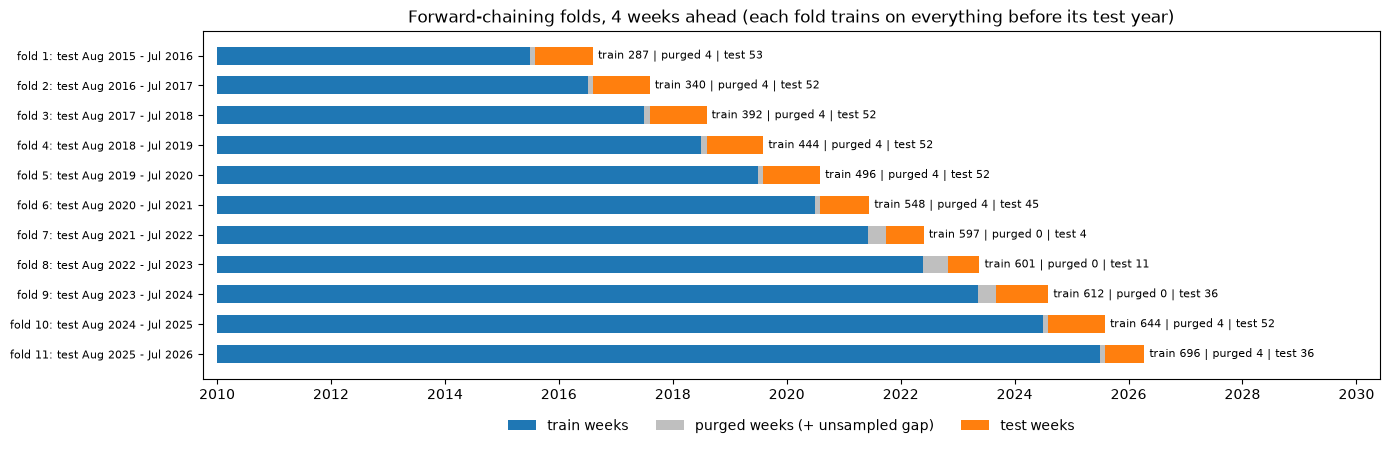

In [2]:
from common.dates import assign_bloom_year
from common.validation import make_folds, select_labelled_rows

NAMES = {0: "no bloom", 1: "at risk", 2: "bloom"}


def fold_table(h):
    """Train and test weeks of every forward-chaining fold for one horizon.

    Args:
        h (int): Weeks ahead (1, 2 or 4).

    Returns:
        pandas.DataFrame: One row per fold with date ranges, class counts and purged weeks.
    """
    t = pd.read_csv(MODELS_ROOT / "notebooks" / "outputs" / "cleaned" / "merged_weekly_sarasota.csv",
                    index_col="week_ending", parse_dates=True)
    lab = select_labelled_rows(t.assign(target=t[f"target_{h}w"], target_week=t.index + pd.Timedelta(weeks=h)))
    label_year = assign_bloom_year(pd.DatetimeIndex(lab["target_week"]))
    rows = []
    for k, (year, tr, te) in enumerate(make_folds(lab, "forward"), start=1):
        purged = ((lab["bloom_year"] < year).to_numpy() & (label_year == year))
        n_tr = lab["target"][tr].value_counts().reindex([0, 1, 2], fill_value=0)
        n_te = lab["target"][te].value_counts().reindex([0, 1, 2], fill_value=0)
        rows.append({"fold": k, "test year": f"Aug {year - 1} - Jul {year}",
                     "train from": lab.index[tr].min().date(), "train to": lab.index[tr].max().date(),
                     "train weeks": int(tr.sum()), **{f"train {NAMES[c]}": int(n_tr[c]) for c in NAMES},
                     "purged weeks": int(purged.sum()),
                     "test from": lab.index[te].min().date(), "test to": lab.index[te].max().date(),
                     "test weeks": int(te.sum()), **{f"test {NAMES[c]}": int(n_te[c]) for c in NAMES}})
    return pd.DataFrame(rows).set_index("fold")

folds_by_h = {h: fold_table(h) for h in (1, 2, 4)}

# Timeline of the folds (4 weeks ahead, where most weeks are purged): training span, purged weeks and test span per fold
f4 = folds_by_h[4]
fig, ax = plt.subplots(figsize=(14, 4.6))
for k, r in f4.iterrows():
    t0, t1 = pd.Timestamp(r["train from"]), pd.Timestamp(r["train to"])
    s0, s1 = pd.Timestamp(r["test from"]), pd.Timestamp(r["test to"])
    ax.barh(k, (t1 - t0).days, left=t0, color="tab:blue", height=0.6, label="train weeks" if k == 1 else None)
    ax.barh(k, (s0 - t1).days, left=t1, color="0.75", height=0.6, label="purged weeks (+ unsampled gap)" if k == 1 else None)
    ax.barh(k, (s1 - s0).days + 7, left=s0, color="tab:orange", height=0.6, label="test weeks" if k == 1 else None)
    ax.text(s1 + pd.Timedelta(days=40), k, f"train {r['train weeks']} | purged {r['purged weeks']} | test {r['test weeks']}",
            va="center", fontsize=8)
ax.invert_yaxis(); ax.xaxis_date()
ax.set_yticks(f4.index, [f"fold {k}: test {r['test year']}" for k, r in f4.iterrows()], fontsize=8)
ax.set_xlim(pd.Timestamp("2009-10-01"), pd.Timestamp("2030-06-01"))
ax.set_title("Forward-chaining folds, 4 weeks ahead (each fold trains on everything before its test year)")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3)
plt.tight_layout(); plt.show()

**What the figure shows.** One row per fold, labelled with its test year; the x-axis is time. Blue = train weeks, grey = purged weeks plus any unsampled gap, orange = test weeks. The numbers at the right of each row are the same counts as the `train weeks`, `purged weeks` and `test weeks` columns in the table below. Each fold's training period ends where the previous fold's test year ends, so the training set grows by one year each time.

**The folds at each horizon.** Training and test date ranges are the weeks whose features are used; each week's label is the class *h* weeks later. `purged weeks` are training weeks removed because their label falls in the test year.

In [3]:
for h, t in folds_by_h.items():
    print(f"{h} week(s) ahead:")
    display(t)

1 week(s) ahead:


,test year,train from,train to,train weeks,train no bloom,train at risk,train bloom,purged weeks,test from,test to,test weeks,test no bloom,test at risk,test bloom
fold,,,,,,,,,,,,,,
1,Aug 2015 - Jul 2016,2010-01-03,2015-07-19,290,254,10,26,1,2015-08-02,2016-07-31,53,22,12,19
2,Aug 2016 - Jul 2017,2010-01-03,2016-07-24,343,276,22,45,1,2016-08-07,2017-07-30,52,18,6,28
3,Aug 2017 - Jul 2018,2010-01-03,2017-07-23,395,294,28,73,1,2017-08-06,2018-07-29,52,29,9,14
4,Aug 2018 - Jul 2019,2010-01-03,2018-07-22,447,324,37,86,1,2018-08-05,2019-07-28,52,29,0,23
5,Aug 2019 - Jul 2020,2010-01-03,2019-07-21,499,352,37,110,1,2019-08-04,2020-07-26,52,44,4,4
6,Aug 2020 - Jul 2021,2010-01-03,2020-07-19,551,396,41,114,1,2020-08-02,2021-06-27,48,28,11,9
7,Aug 2021 - Jul 2022,2010-01-03,2021-06-27,600,425,52,123,0,2021-10-17,2022-06-12,4,3,1,0
8,Aug 2022 - Jul 2023,2010-01-03,2022-06-12,604,428,53,123,0,2022-11-20,2023-06-04,11,5,0,6
9,Aug 2023 - Jul 2024,2010-01-03,2023-06-04,615,433,53,129,0,2023-09-24,2024-07-28,33,33,0,0


2 week(s) ahead:


,test year,train from,train to,train weeks,train no bloom,train at risk,train bloom,purged weeks,test from,test to,test weeks,test no bloom,test at risk,test bloom
fold,,,,,,,,,,,,,,
1,Aug 2015 - Jul 2016,2010-01-03,2015-07-12,289,253,10,26,2,2015-08-02,2016-07-31,53,22,12,19
2,Aug 2016 - Jul 2017,2010-01-03,2016-07-17,342,275,22,45,2,2016-08-07,2017-07-30,52,18,6,28
3,Aug 2017 - Jul 2018,2010-01-03,2017-07-16,394,293,28,73,2,2017-08-06,2018-07-29,52,28,9,15
4,Aug 2018 - Jul 2019,2010-01-03,2018-07-15,446,323,37,86,2,2018-08-05,2019-07-28,52,30,0,22
5,Aug 2019 - Jul 2020,2010-01-03,2019-07-14,498,351,37,110,2,2019-08-04,2020-07-26,52,44,4,4
6,Aug 2020 - Jul 2021,2010-01-03,2020-07-12,550,395,41,114,2,2020-08-02,2021-06-20,47,27,11,9
7,Aug 2021 - Jul 2022,2010-01-03,2021-06-20,599,424,52,123,0,2021-10-10,2022-06-05,4,3,1,0
8,Aug 2022 - Jul 2023,2010-01-03,2022-06-05,603,427,53,123,0,2022-11-13,2023-05-28,11,5,0,6
9,Aug 2023 - Jul 2024,2010-01-03,2023-05-28,614,432,53,129,0,2023-09-17,2024-07-28,34,34,0,0


4 week(s) ahead:


,test year,train from,train to,train weeks,train no bloom,train at risk,train bloom,purged weeks,test from,test to,test weeks,test no bloom,test at risk,test bloom
fold,,,,,,,,,,,,,,
1,Aug 2015 - Jul 2016,2010-01-03,2015-06-28,287,251,10,26,4,2015-08-02,2016-07-31,53,22,12,19
2,Aug 2016 - Jul 2017,2010-01-03,2016-07-03,340,273,22,45,4,2016-08-07,2017-07-30,52,18,6,28
3,Aug 2017 - Jul 2018,2010-01-03,2017-07-02,392,291,28,73,4,2017-08-06,2018-07-29,52,26,9,17
4,Aug 2018 - Jul 2019,2010-01-03,2018-07-01,444,321,37,86,4,2018-08-05,2019-07-28,52,32,0,20
5,Aug 2019 - Jul 2020,2010-01-03,2019-06-30,496,349,37,110,4,2019-08-04,2020-07-26,52,43,5,4
6,Aug 2020 - Jul 2021,2010-01-03,2020-06-28,548,393,41,114,4,2020-08-02,2021-06-06,45,26,10,9
7,Aug 2021 - Jul 2022,2010-01-03,2021-06-06,597,422,52,123,0,2021-09-26,2022-05-22,4,3,1,0
8,Aug 2022 - Jul 2023,2010-01-03,2022-05-22,601,425,53,123,0,2022-10-30,2023-05-14,11,5,0,6
9,Aug 2023 - Jul 2024,2010-01-03,2023-05-14,612,430,53,129,0,2023-09-03,2024-07-28,36,36,0,0


**Result.**

* **Training grows each fold:** at 1 week ahead from 290 weeks (fold 1) to 699 (fold 11); at 4 weeks from 287 to 696. At-risk weeks stay rare throughout.
* **Purging removes *h* weeks per fold** (1, 2 or 4): the last *h* training weeks before the test year. Folds 7–9 lose none, because sampling stopped well before those test years began, so their last training weeks are already months earlier.
* **Some test years are small:** fold 7 (Aug 2021 – Jul 2022) has 4 test weeks and fold 8 has 11, because sampling nearly stopped in 2021–2023. Their scores below are noisy.

---
## 2. Persistence

**What it is.** Next week's class = the most recently observed class. It has no parameters and uses no features except the last observed class. This is the naïve forecast, the standard benchmark every forecasting method should beat [1].

**Why it matters here.** The class rarely changes from one week to the next (94 % of no-bloom weeks stay no bloom, 84 % of bloom weeks stay bloom; `00_master_eda_and_merge.ipynb` §10.10), so persistence is hard to beat on overall accuracy. By design it can never predict a change.

**Source**
1. Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and Practice* (3rd ed.), OTexts. https://otexts.com/fpp3/, §5.2 Some simple forecasting methods (naïve method).

In [4]:
model_table("persistence")

,,accuracy,macro-F1,at-risk recall,bloom recall,warning recall,warning precision,onsets flagged (of 11),escalations caught,bloom PR-AUC
horizon,feature_set,,,,,,,,,
h1w,kb_only,0.83,0.71,0.36,0.86,0.85,0.85,7,0.0,0.77
h2w,kb_only,0.79,0.65,0.28,0.80,0.80,0.80,5,0.0,0.69
h4w,kb_only,0.74,0.60,0.24,0.70,0.74,0.75,5,0.0,0.59


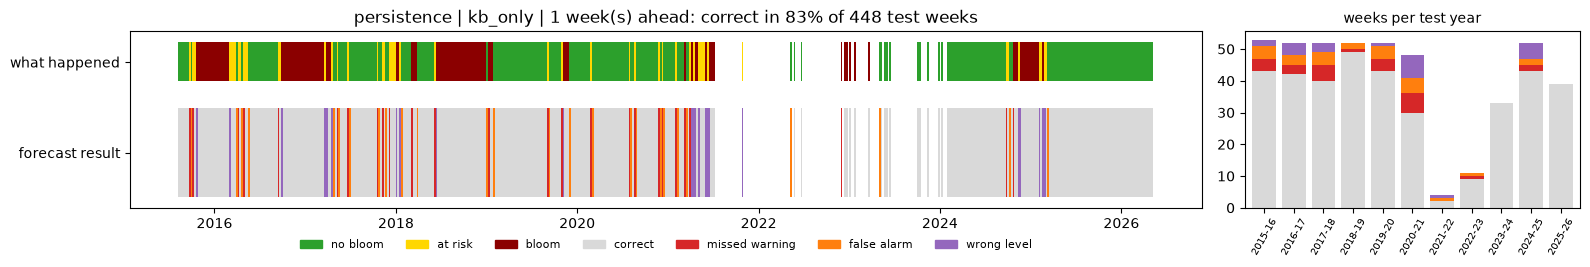

In [5]:
timeline("persistence", "kb_only")

**Score per test year** (1 week ahead, `kb_only`):

In [6]:
by_year("persistence", "kb_only")

,Aug 2015 - Jul 2016,Aug 2016 - Jul 2017,Aug 2017 - Jul 2018,Aug 2018 - Jul 2019,Aug 2019 - Jul 2020,Aug 2020 - Jul 2021,Aug 2021 - Jul 2022,Aug 2022 - Jul 2023,Aug 2023 - Jul 2024,Aug 2024 - Jul 2025,Aug 2025 - Jul 2026
test weeks,53.00,52.00,52.00,52.00,52.00,48.00,4.00,11.00,33.00,52.00,39.00
accuracy,0.81,0.81,0.77,0.94,0.83,0.62,0.50,0.82,1.00,0.83,1.00
macro-F1,0.78,0.64,0.70,0.63,0.55,0.52,0.27,0.54,0.33,0.72,0.33


**How to read the chart.** Left: time over the test years, one block per week. The thin top strip is **what happened** (green = no bloom, yellow = at risk, dark red = bloom). The wide strip is **how the forecast did** that week:

* light grey = **correct**
* red = **missed warning**: at risk or bloom happened, but no bloom was forecast
* orange = **false alarm**: a warning was forecast, but there was no bloom
* purple = **wrong level**: at risk and bloom mixed up

Right: the same four outcomes counted per test year. Blank stretches are weeks with no sample.

For persistence, the red marks sit at the start of each yellow or dark-red stretch (it notices a change one week late), and the orange marks at the end (it keeps warning one week after a bloom ends).

**Findings**
* **The bar to beat:** macro-F1 0.71 at 1 week, 0.65 at 2 weeks and 0.60 at 4 weeks.
* **Warnings are reliable but late:** warning precision 0.75–0.85, but only 5–7 of 11 bloom onsets get a warning, and no escalation is ever caught (0 %).

---
## 3. Seasonal climatology

**What it is.** For each week of the year (± 3 weeks), the share of past weeks in each class, adjusted for how rare each class is; the forecast is the most likely class for that time of year. It uses only the date.

**Why test it.** Blooms are strongly seasonal (1 % of sampled weeks at bloom level in May, 47 % in November). This shows how much of the forecast season alone can explain.

In [7]:
model_table("seasonal_climatology")

,,accuracy,macro-F1,at-risk recall,bloom recall,warning recall,warning precision,onsets flagged (of 11),escalations caught,bloom PR-AUC
horizon,feature_set,,,,,,,,,
h1w,kb_only,0.4,0.37,0.28,0.62,0.82,0.42,9,0.77,0.42
h2w,kb_only,0.4,0.37,0.28,0.62,0.82,0.42,9,0.79,0.42
h4w,kb_only,0.4,0.37,0.28,0.62,0.82,0.42,9,0.81,0.42


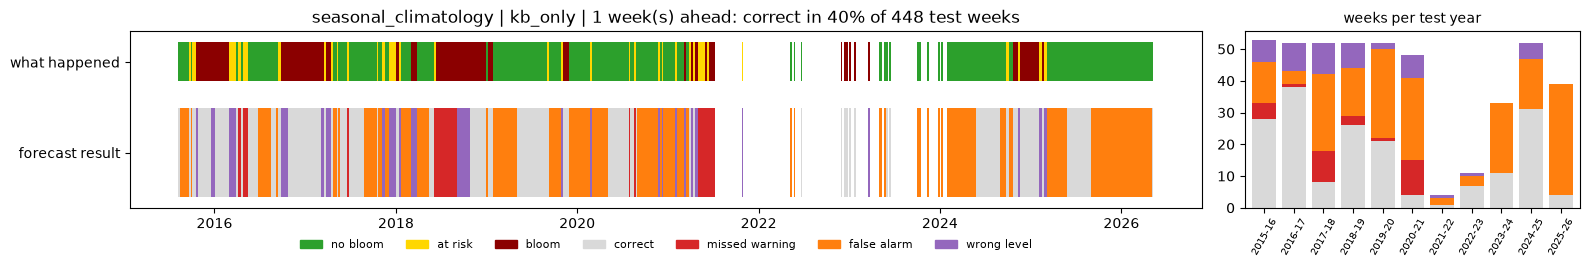

In [8]:
timeline("seasonal_climatology", "kb_only")

**Score per test year** (1 week ahead, `kb_only`):

In [9]:
by_year("seasonal_climatology", "kb_only")

,Aug 2015 - Jul 2016,Aug 2016 - Jul 2017,Aug 2017 - Jul 2018,Aug 2018 - Jul 2019,Aug 2019 - Jul 2020,Aug 2020 - Jul 2021,Aug 2021 - Jul 2022,Aug 2022 - Jul 2023,Aug 2023 - Jul 2024,Aug 2024 - Jul 2025,Aug 2025 - Jul 2026
test weeks,53.00,52.00,52.00,52.00,52.00,48.00,4.00,11.00,33.00,52.00,39.00
accuracy,0.53,0.73,0.15,0.50,0.40,0.08,0.25,0.64,0.33,0.60,0.10
macro-F1,0.50,0.69,0.14,0.39,0.32,0.08,0.17,0.49,0.17,0.55,0.06


**Findings**
* **Weak overall:** macro-F1 0.37 at every horizon (the same season gives the same forecast whatever happened recently).
* **Many false alarms:** it warns in most autumn weeks, so warning recall is high (0.82) but warning precision is low (0.42).
* Season alone is not enough; it is used as a feature in the other models instead.

---
## 4. Logistic regression

**What it is.** A multinomial logistic regression: each class's log-odds is a weighted sum of the features. The weights can be read directly, which suits the project's aim of interpretable drivers [1].

**Set-up** (`logistic_regression/train.py`)
* Missing values filled with the training median, plus a "was missing" indicator for each feature.
* Features standardised. Both steps are fitted inside each training fold only, so test years never influence them.
* Strong L2 penalty (C = 0.1), because there are about 740 labelled weeks and up to 60 correlated features.
* Class weights balanced, so at-risk and bloom weeks count as much as no-bloom weeks.

**Source**
1. Biointerphase 1A, *Challenge Project Overview*, Suggested Approach (recommended methods include Random Forest and Gradient Boosting; success includes identifying at-risk conditions and interpretable drivers).

In [10]:
model_table("logistic_regression")

accuracy  macro-F1  at-risk recall  bloom recall  warning recall  warning precision  onsets flagged (of 11)  escalations caught  bloom PR-AUC
horizon feature_set                                                                                                                                               
h1w     kb_only          0.77      0.65            0.38          0.72            0.85               0.79                       9                0.31          0.89
        full             0.74      0.61            0.24          0.77            0.83               0.73                       7                0.31          0.87
        long             0.69      0.58            0.28          0.72            0.85               0.68                       7                0.38          0.87
        env_only         0.29      0.27            0.16          0.43            0.73               0.37                       8                0.69          0.36
h2w     kb_only          0.73      0.60            0.34          0.67            0.85               0.74                       8                0.38          0.80
        long             0.66      0.57            0.28          0.76            0.85               0.62                       9                0.47          0.82
        full             0.70      0.56            0.16          0.75            0.82               0.69                       9                0.41          0.80
        env_only         0.35      0.32            0.22          0.55            0.73               0.38                      10                0.74          0.40
h4w     kb_only          0.71      0.57            0.20          0.70            0.75               0.71                       5                0.19          0.72
        full             0.66      0.57            0.34          0.71            0.80               0.61                       6                0.51          0.75
        long             0.61      0.55            0.48          0.64            0.85               0.57                       7                0.63          0.74
        env_only         0.31      0.28            0.24          0.38            0.70               0.37                       9                0.77          0.38

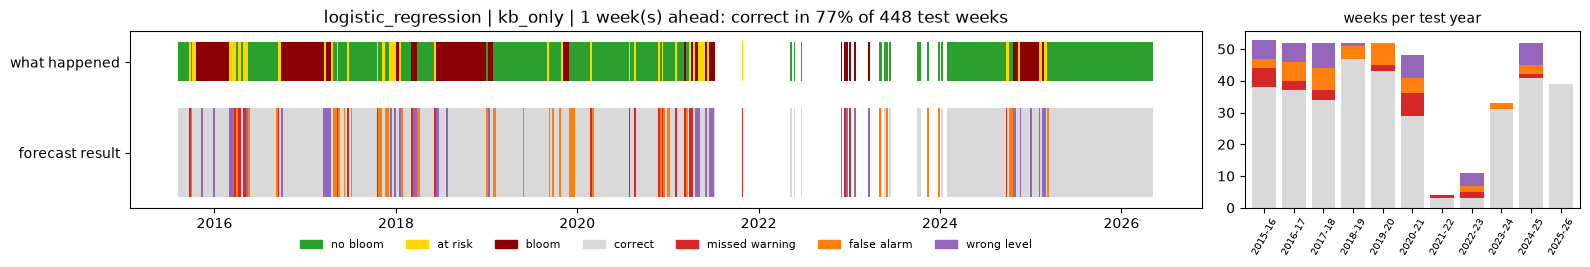

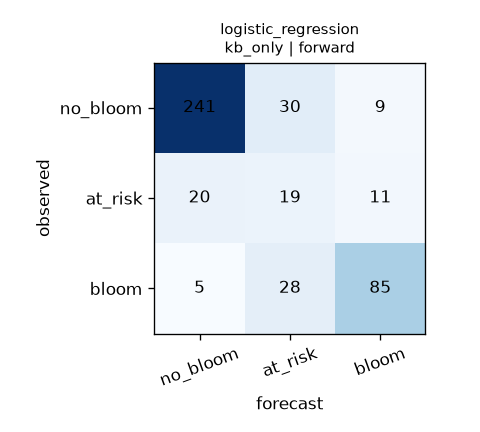

In [11]:
timeline("logistic_regression", "kb_only")
show("logistic_regression", "kb_only", kind="confusion")

**Score per test year** (1 week ahead, `kb_only`):

In [12]:
by_year("logistic_regression", "kb_only")

,Aug 2015 - Jul 2016,Aug 2016 - Jul 2017,Aug 2017 - Jul 2018,Aug 2018 - Jul 2019,Aug 2019 - Jul 2020,Aug 2020 - Jul 2021,Aug 2021 - Jul 2022,Aug 2022 - Jul 2023,Aug 2023 - Jul 2024,Aug 2024 - Jul 2025,Aug 2025 - Jul 2026
test weeks,53.00,52.00,52.00,52.00,52.00,48.00,4.00,11.00,33.00,52.00,39.00
accuracy,0.72,0.71,0.65,0.90,0.83,0.60,0.75,0.27,0.94,0.79,1.00
macro-F1,0.62,0.61,0.59,0.62,0.69,0.45,0.29,0.20,0.32,0.70,0.33


**What the figures show.** Timeline: read as in §2 (red = missed warning, orange = false alarm, purple = wrong level). Confusion matrix: for each true class (rows), how the weeks were predicted (columns).

**Findings**
* **Best on bloom history alone (`kb_only`):** macro-F1 0.65 at 1 week, 0.61 at 2 weeks, 0.57 at 4 weeks. Below persistence at every horizon.
* **Environment alone is weak** (`env_only` macro-F1 0.27–0.32).
* **Adding the environment lowers macro-F1 at 1 week** (0.65 → 0.58 for `long`) but raises escalations caught at 4 weeks (0.19 → 0.51–0.63).
* **Good risk ranking:** bloom PR-AUC 0.89 at 1 week, against 0.77 for persistence.

---
## 5. Random forest

**What it is.** Many decision trees, each trained on a random sample of weeks and features; the forecast is their vote. Trees can capture thresholds and interactions, need no scaling, and handle missing values. Random forest is a recommended method in the project brief [1] and is the model in Medina et al.'s *K. brevis* early-warning forecast [2].

**Set-up** (`random_forest/train.py`): 500 trees, at least 3 weeks per leaf, √(number of features) per split, class weights balanced per tree.

**Sources**
1. Biointerphase 1A, *Challenge Project Overview*, Suggested Approach (recommended methods include Random Forest and Gradient Boosting; success includes identifying at-risk conditions and interpretable drivers).
2. Medina, M., Julian, P., Chin, N., & Davis, S. E. (2024). An early-warning forecast model for red tide (*Karenia brevis*) blooms on the southwest coast of Florida. *Harmful Algae*, 139, 102729. https://doi.org/10.1016/j.hal.2024.102729

In [13]:
model_table("random_forest")

accuracy  macro-F1  at-risk recall  bloom recall  warning recall  warning precision  onsets flagged (of 11)  escalations caught  bloom PR-AUC
horizon feature_set                                                                                                                                               
h1w     kb_only          0.82      0.66            0.22          0.86            0.80               0.83                       6                0.08          0.91
        long             0.82      0.64            0.16          0.85            0.80               0.88                       5                0.08          0.92
        full             0.82      0.64            0.16          0.84            0.79               0.87                       4                0.04          0.92
        env_only         0.60      0.40            0.00          0.48            0.48               0.54                       6                0.46          0.37
h2w     full             0.80      0.58            0.04          0.85            0.74               0.85                       4                0.03          0.86
        kb_only          0.79      0.57            0.04          0.85            0.74               0.82                       5                0.00          0.82
        long             0.80      0.57            0.02          0.86            0.73               0.84                       4                0.00          0.85
        env_only         0.61      0.40            0.00          0.48            0.46               0.54                       7                0.53          0.37
h4w     full             0.76      0.52            0.00          0.71            0.59               0.82                       1                0.00          0.78
        long             0.76      0.52            0.00          0.72            0.61               0.80                       2                0.02          0.77
        kb_only          0.73      0.51            0.02          0.73            0.62               0.72                       2                0.00          0.71
        env_only         0.61      0.40            0.00          0.49            0.48               0.55                       6                0.49          0.38

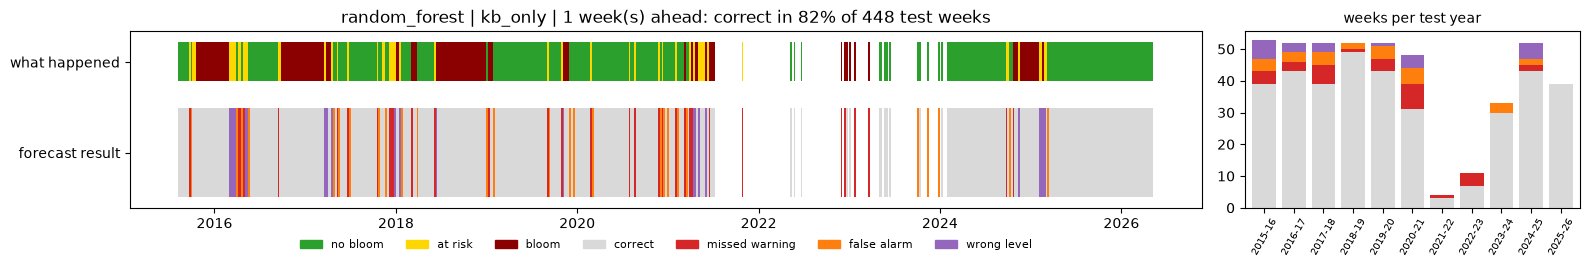

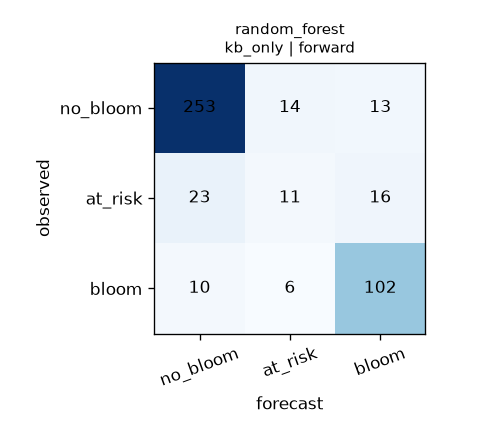

In [14]:
timeline("random_forest", "kb_only")
show("random_forest", "kb_only", kind="confusion")

**Score per test year** (1 week ahead, `kb_only`):

In [15]:
by_year("random_forest", "kb_only")

,Aug 2015 - Jul 2016,Aug 2016 - Jul 2017,Aug 2017 - Jul 2018,Aug 2018 - Jul 2019,Aug 2019 - Jul 2020,Aug 2020 - Jul 2021,Aug 2021 - Jul 2022,Aug 2022 - Jul 2023,Aug 2023 - Jul 2024,Aug 2024 - Jul 2025,Aug 2025 - Jul 2026
test weeks,53.00,52.00,52.00,52.00,52.00,48.00,4.00,11.00,33.00,52.00,39.00
accuracy,0.74,0.83,0.75,0.94,0.83,0.65,0.75,0.64,0.91,0.83,1.00
macro-F1,0.63,0.65,0.64,0.63,0.55,0.55,0.29,0.40,0.32,0.69,0.33


**Findings**
* **Best plain model at 1 week:** macro-F1 0.66 on `kb_only`, still below persistence (0.71).
* **Best risk ranking of all models:** bloom PR-AUC 0.91–0.92 at 1 week.
* **Almost never predicts at risk:** at-risk recall 0.00–0.22, and it catches almost no escalations (0–8 %). Its forecasts mostly follow the last class.
* **Falls off at 4 weeks:** macro-F1 0.51–0.52 and only 1–2 of 11 onsets flagged.

---
## 6. XGBoost

**What it is.** Gradient-boosted trees: small trees added one at a time, each correcting the errors of the ones before. Gradient boosting is a recommended method in the project brief [1]; Izadi et al. found XGBoost outperformed random forest and SVM for forecasting Florida HAB onset from satellite data [2].

**Set-up** (`xgboost/train.py`): 300 shallow trees (depth 3), learning rate 0.05, 80 % of weeks and features per tree, balanced sample weights. Kept small and slow because of the small data.

**Sources**
1. Biointerphase 1A, *Challenge Project Overview*, Suggested Approach (recommended methods include Random Forest and Gradient Boosting; success includes identifying at-risk conditions and interpretable drivers).
2. Izadi, M., Sultan, M., El Kadiri, R., et al. (2021). A remote sensing and machine learning-based approach to forecast the onset of harmful algal bloom. *Remote Sensing*, 13(19), 3863. https://doi.org/10.3390/rs13193863

In [16]:
model_table("xgboost")

accuracy  macro-F1  at-risk recall  bloom recall  warning recall  warning precision  onsets flagged (of 11)  escalations caught  bloom PR-AUC
horizon feature_set                                                                                                                                               
h1w     kb_only          0.79      0.64            0.22          0.79            0.80               0.82                       7                0.15          0.90
        full             0.82      0.63            0.12          0.86            0.77               0.87                       7                0.08          0.91
        long             0.81      0.61            0.10          0.86            0.79               0.84                       8                0.15          0.90
        env_only         0.54      0.39            0.02          0.53            0.56               0.48                       7                0.54          0.39
h2w     full             0.79      0.57            0.04          0.81            0.74               0.86                       7                0.12          0.86
        long             0.77      0.57            0.06          0.81            0.73               0.79                       7                0.09          0.85
        kb_only          0.76      0.56            0.06          0.73            0.72               0.81                       6                0.12          0.84
        env_only         0.54      0.37            0.02          0.47            0.50               0.47                       8                0.53          0.34
h4w     long             0.71      0.53            0.08          0.69            0.66               0.72                       4                0.21          0.77
        kb_only          0.73      0.53            0.04          0.72            0.61               0.72                       3                0.19          0.75
        full             0.72      0.51            0.04          0.64            0.59               0.74                       2                0.14          0.76
        env_only         0.57      0.40            0.04          0.47            0.49               0.51                       5                0.47          0.37

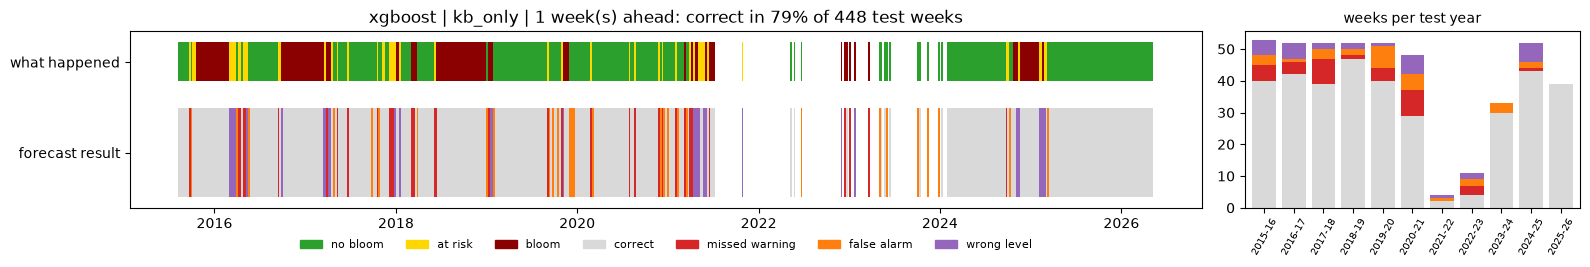

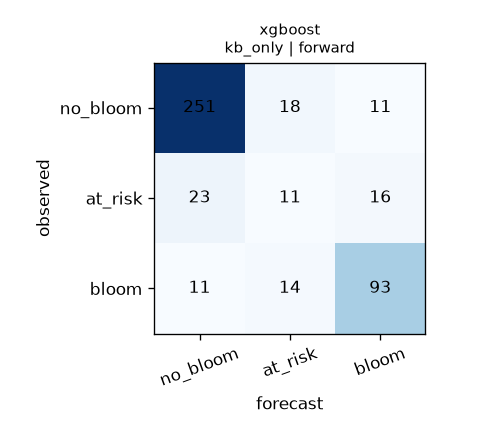

In [17]:
timeline("xgboost", "kb_only")
show("xgboost", "kb_only", kind="confusion")

**Score per test year** (1 week ahead, `kb_only`):

In [18]:
by_year("xgboost", "kb_only")

,Aug 2015 - Jul 2016,Aug 2016 - Jul 2017,Aug 2017 - Jul 2018,Aug 2018 - Jul 2019,Aug 2019 - Jul 2020,Aug 2020 - Jul 2021,Aug 2021 - Jul 2022,Aug 2022 - Jul 2023,Aug 2023 - Jul 2024,Aug 2024 - Jul 2025,Aug 2025 - Jul 2026
test weeks,53.00,52.00,52.00,52.00,52.00,48.00,4.00,11.00,33.00,52.00,39.00
accuracy,0.75,0.81,0.75,0.90,0.77,0.60,0.50,0.36,0.91,0.83,1.00
macro-F1,0.65,0.69,0.64,0.62,0.51,0.48,0.27,0.28,0.32,0.69,0.33


**Findings**
* **Similar to random forest:** macro-F1 0.64 at 1 week on `kb_only`, 0.51–0.53 at 4 weeks.
* **Strong risk ranking** (bloom PR-AUC 0.90 at 1 week), but at-risk recall is low (0.04–0.22) and, with bloom history included, few escalations are caught (8–21 %).

---
## 7. Persistence + escalation (hybrid)

**What it is.** The learned models rank risk well (high PR-AUC) but lose the steady weeks that persistence gets right, while persistence can never forecast a change. The hybrid combines them:

* By default, forecast the **last observed class** (persistence).
* If that class was **no bloom** and a learned model's probability of at risk or bloom is above a threshold, **escalate** to at risk or bloom (whichever the model finds more likely).
* The threshold is tuned on the training years only (an inner leave-one-year-out loop), never on the test year.

Two versions: **Hybrid LR** (logistic regression base) and **Hybrid XGB** (XGBoost base), each on `kb_only`, `long` and `full` (`hybrid_escalation/train.py`).

In [19]:
pd.concat({"Hybrid LR": model_table("hybrid_lr"), "Hybrid XGB": model_table("hybrid_xgb")})

accuracy  macro-F1  at-risk recall  bloom recall  warning recall  warning precision  onsets flagged (of 11)  escalations caught  bloom PR-AUC
           horizon feature_set                                                                                                                                               
Hybrid LR  h1w     kb_only          0.81      0.71            0.44          0.86            0.88               0.79                       8                0.19          0.89
                   full             0.78      0.68            0.42          0.86            0.89               0.74                       9                0.27          0.87
                   long             0.76      0.66            0.42          0.86            0.89               0.71                       9                0.27          0.87
           h2w     kb_only          0.77      0.66            0.40          0.80            0.86               0.74                       8                0.29          0.80
                   full             0.74      0.64            0.36          0.82            0.86               0.70                       8                0.32          0.80
                   long             0.69      0.61            0.40          0.82            0.88               0.62                       9                0.41          0.82
           h4w     kb_only          0.69      0.58            0.28          0.73            0.79               0.66                       5                0.16          0.72
                   full             0.63      0.57            0.46          0.75            0.88               0.58                       9                0.53          0.75
                   long             0.59      0.55            0.56          0.74            0.92               0.54                       9                0.67          0.74
Hybrid XGB h1w     kb_only          0.81      0.70            0.42          0.86            0.86               0.78                       7                0.12          0.90
                   full             0.77      0.67            0.44          0.86            0.89               0.72                       9                0.27          0.91
                   long             0.74      0.65            0.46          0.86            0.89               0.67                       9                0.31          0.90
           h2w     kb_only          0.73      0.61            0.30          0.82            0.85               0.69                       8                0.26          0.84
                   full             0.71      0.61            0.36          0.80            0.86               0.67                       9                0.32          0.86
                   long             0.70      0.61            0.38          0.81            0.88               0.65                       9                0.38          0.85
           h4w     long             0.64      0.55            0.38          0.73            0.87               0.60                       8                0.49          0.77
                   full             0.62      0.54            0.38          0.75            0.88               0.58                       8                0.53          0.76
                   kb_only          0.58      0.51            0.32          0.75            0.88               0.54                       8                0.51          0.75

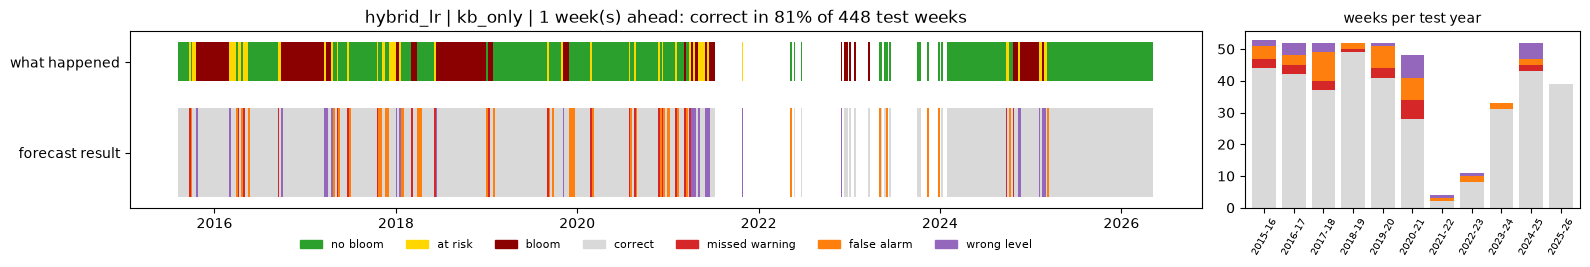

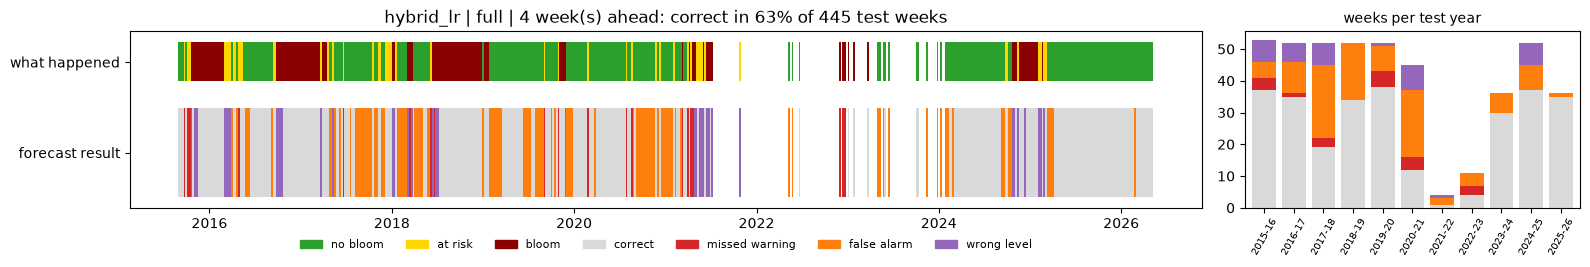

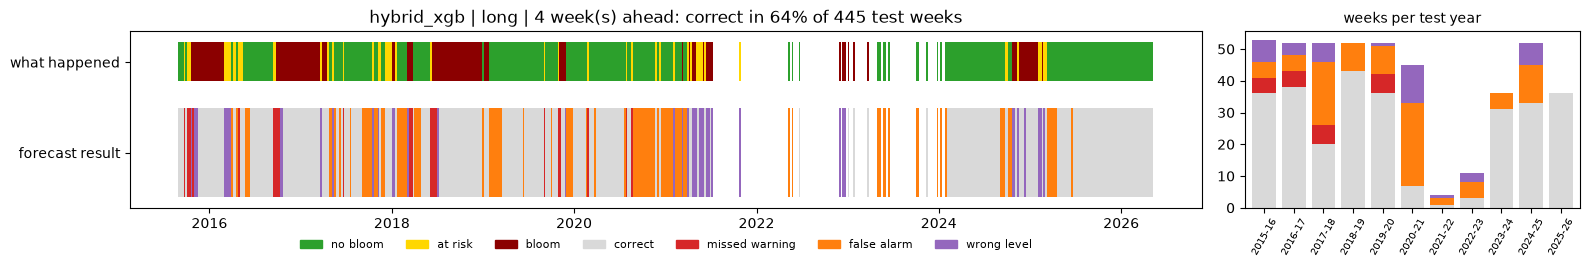

In [20]:
timeline("hybrid_lr", "kb_only")
timeline("hybrid_lr", "full", horizon="h4w")
timeline("hybrid_xgb", "long", horizon="h4w")

**Score per test year:** Hybrid LR at 1 week (`kb_only`), then at 4 weeks (`full`):

In [21]:
display(by_year("hybrid_lr", "kb_only"))
by_year("hybrid_lr", "full", horizon="h4w")

,Aug 2015 - Jul 2016,Aug 2016 - Jul 2017,Aug 2017 - Jul 2018,Aug 2018 - Jul 2019,Aug 2019 - Jul 2020,Aug 2020 - Jul 2021,Aug 2021 - Jul 2022,Aug 2022 - Jul 2023,Aug 2023 - Jul 2024,Aug 2024 - Jul 2025,Aug 2025 - Jul 2026
test weeks,53.00,52.00,52.00,52.00,52.00,48.00,4.00,11.00,33.00,52.00,39.00
accuracy,0.83,0.81,0.71,0.94,0.79,0.58,0.50,0.73,0.94,0.83,1.00
macro-F1,0.81,0.64,0.69,0.63,0.58,0.49,0.27,0.53,0.32,0.72,0.33


,Aug 2015 - Jul 2016,Aug 2016 - Jul 2017,Aug 2017 - Jul 2018,Aug 2018 - Jul 2019,Aug 2019 - Jul 2020,Aug 2020 - Jul 2021,Aug 2021 - Jul 2022,Aug 2022 - Jul 2023,Aug 2023 - Jul 2024,Aug 2024 - Jul 2025,Aug 2025 - Jul 2026
test weeks,53.00,52.00,52.00,52.00,52.00,45.00,4.00,11.00,36.00,52.00,36.00
accuracy,0.70,0.67,0.37,0.65,0.73,0.27,0.25,0.36,0.83,0.71,0.97
macro-F1,0.65,0.58,0.37,0.49,0.45,0.27,0.17,0.24,0.30,0.63,0.33


**What the figures show.** Top: Hybrid LR on bloom history, 1 week ahead. Middle: Hybrid LR on `full`, 4 weeks ahead. Bottom: Hybrid XGB on `long`, 4 weeks ahead (read as in §2). In the 4-week chart, orange false alarms fill long quiet stretches such as 2019–2021, while red missed warnings are rarer than for persistence.

**Findings**
* **1 week: Hybrid LR (`kb_only`) ties persistence** on macro-F1 (0.71 vs 0.71) while raising at-risk recall (0.36 → 0.44) and warning recall (0.85 → 0.88) and catching 19 % of escalations.
* **2 weeks: the same tie** (Hybrid LR 0.66 vs persistence 0.65), with warning recall 0.80 → 0.86 and 29 % of escalations caught.
* **4 weeks: the hybrids trade precision for early warning.** Hybrid LR on `full` flags 9 of 11 onsets and Hybrid XGB on `long` 8 of 11 (persistence: 5), catching 54 % and 49 % of escalations, but warning precision drops to 0.58–0.60 (about 4 in 10 warnings are false alarms). Macro-F1 is lower (0.55–0.57 vs 0.60).

---
## 8. Comparison

**Best version of each model** (the feature set with the highest macro-F1) at each horizon:

In [22]:
best = results.loc[results.groupby(["horizon", "model"])["macro_f1"].idxmax()]
best = best.set_index(["horizon", "model"])[["feature_set"] + list(METRICS)].rename(columns=METRICS)
best.sort_values(["horizon", "macro-F1"], ascending=[True, False]).round(2)

feature_set  accuracy  macro-F1  at-risk recall  bloom recall  warning recall  warning precision  onsets flagged (of 11)  escalations caught  bloom PR-AUC
horizon model                                                                                                                                                                          
h1w     persistence              kb_only      0.83      0.71            0.36          0.86            0.85               0.85                       7                0.00          0.77
        hybrid_lr                kb_only      0.81      0.71            0.44          0.86            0.88               0.79                       8                0.19          0.89
        hybrid_xgb               kb_only      0.81      0.70            0.42          0.86            0.86               0.78                       7                0.12          0.90
        random_forest            kb_only      0.82      0.66            0.22          0.86            0.80               0.83                       6                0.08          0.91
        logistic_regression      kb_only      0.77      0.65            0.38          0.72            0.85               0.79                       9                0.31          0.89
        xgboost                  kb_only      0.79      0.64            0.22          0.79            0.80               0.82                       7                0.15          0.90
        seasonal_climatology     kb_only      0.40      0.37            0.28          0.62            0.82               0.42                       9                0.77          0.42
h2w     hybrid_lr                kb_only      0.77      0.66            0.40          0.80            0.86               0.74                       8                0.29          0.80
        persistence              kb_only      0.79      0.65            0.28          0.80            0.80               0.80                       5                0.00          0.69
        hybrid_xgb               kb_only      0.73      0.61            0.30          0.82            0.85               0.69                       8                0.26          0.84
        logistic_regression      kb_only      0.73      0.60            0.34          0.67            0.85               0.74                       8                0.38          0.80
        random_forest               full      0.80      0.58            0.04          0.85            0.74               0.85                       4                0.03          0.86
        xgboost                     full      0.79      0.57            0.04          0.81            0.74               0.86                       7                0.12          0.86
        seasonal_climatology     kb_only      0.40      0.37            0.28          0.62            0.82               0.42                       9                0.79          0.42
h4w     persistence              kb_only      0.74      0.60            0.24          0.70            0.74               0.75                       5                0.00          0.59
        hybrid_lr                kb_only      0.69      0.58            0.28          0.73            0.79               0.66                       5                0.16          0.72
        logistic_regression      kb_only      0.71      0.57            0.20          0.70            0.75               0.71                       5                0.19          0.72
        hybrid_xgb                  long      0.64      0.55            0.38          0.73            0.87               0.60                       8                0.49          0.77
        xgboost                     long      0.71      0.53            0.08          0.69            0.66               0.72                       4                0.21          0.77
        random_forest               full      0.76      0.52            0.00          0.71            0.59               0.82                       1                

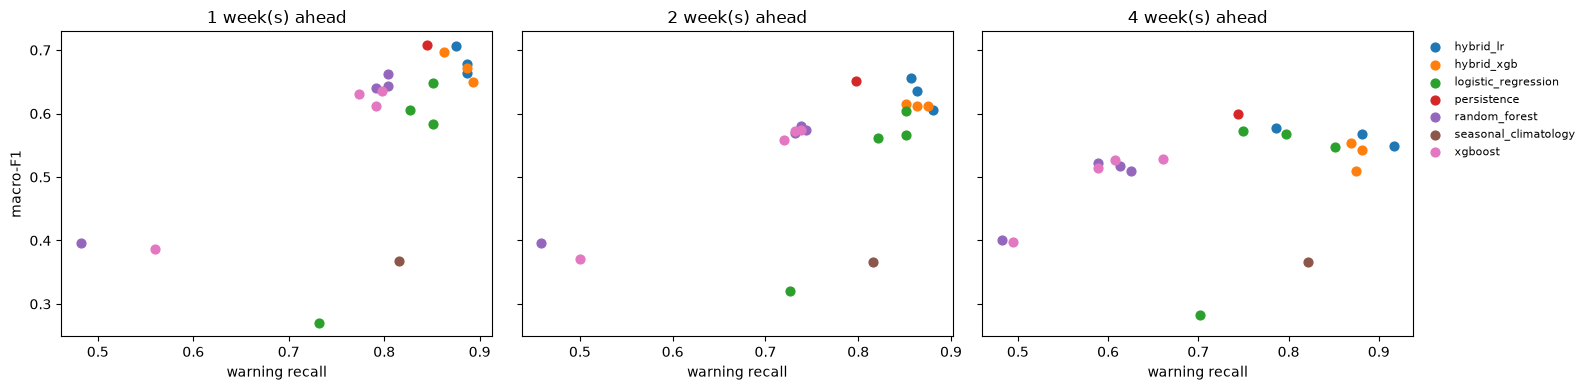

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, h in zip(axes, ["h1w", "h2w", "h4w"]):
    d = results[results["horizon"] == h]
    for m, g in d.groupby("model"):
        ax.scatter(g["warning_recall"], g["macro_f1"], s=40, label=m)
    ax.set_title(f"{h[1]} week(s) ahead"); ax.set_xlabel("warning recall")
axes[0].set_ylabel("macro-F1"); axes[-1].legend(frameon=False, fontsize=8, bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()

**What the figure shows.** Each dot is one model and feature set. The y-axis is macro-F1 (overall accuracy across the three classes) and the x-axis is warning recall (how many real warnings are flagged). Up and to the right is better. Persistence sits high on macro-F1; the hybrids reach further right (more warnings) at a similar or slightly lower macro-F1.

**Score per test year, 1 week ahead** (each model on `kb_only`):

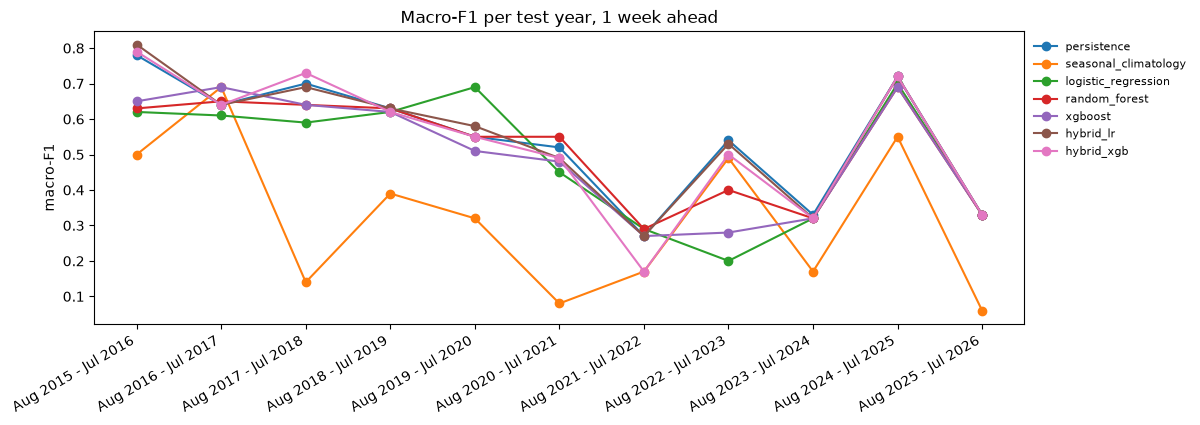

,Aug 2015 - Jul 2016,Aug 2016 - Jul 2017,Aug 2017 - Jul 2018,Aug 2018 - Jul 2019,Aug 2019 - Jul 2020,Aug 2020 - Jul 2021,Aug 2021 - Jul 2022,Aug 2022 - Jul 2023,Aug 2023 - Jul 2024,Aug 2024 - Jul 2025,Aug 2025 - Jul 2026
persistence,0.78,0.64,0.70,0.63,0.55,0.52,0.27,0.54,0.33,0.72,0.33
seasonal_climatology,0.50,0.69,0.14,0.39,0.32,0.08,0.17,0.49,0.17,0.55,0.06
logistic_regression,0.62,0.61,0.59,0.62,0.69,0.45,0.29,0.20,0.32,0.70,0.33
random_forest,0.63,0.65,0.64,0.63,0.55,0.55,0.29,0.40,0.32,0.69,0.33
xgboost,0.65,0.69,0.64,0.62,0.51,0.48,0.27,0.28,0.32,0.69,0.33
hybrid_lr,0.81,0.64,0.69,0.63,0.58,0.49,0.27,0.53,0.32,0.72,0.33
hybrid_xgb,0.79,0.64,0.73,0.62,0.55,0.49,0.17,0.50,0.32,0.72,0.33


In [24]:
yearly = pd.DataFrame({m: by_year(m, "kb_only").loc["macro-F1"] for m in
                       ["persistence", "seasonal_climatology", "logistic_regression", "random_forest", "xgboost", "hybrid_lr", "hybrid_xgb"]})
ax = yearly.plot(marker="o", figsize=(12, 3.8)); ax.set_ylabel("macro-F1"); ax.set_title("Macro-F1 per test year, 1 week ahead")
ax.legend(frameon=False, fontsize=8, bbox_to_anchor=(1, 1)); plt.xticks(range(len(yearly)), yearly.index, rotation=30, ha="right"); plt.show()
yearly.round(2).T

**Result.** Scores swing a lot from year to year: persistence ranges from macro-F1 0.27 to 0.78. Two things to keep in mind when reading the table:

* **Quiet years.** In Aug 2023 – Jul 2024 and Aug 2025 – Jul 2026 every test week was no bloom. Persistence gets accuracy 1.00 there but macro-F1 0.33, because the two classes that never occur score 0. This is why macro-F1, not accuracy, is the main score.
* **Small years.** Aug 2021 – Jul 2022 (4 weeks) and Aug 2022 – Jul 2023 (11 weeks) have very few test weeks, so one week changes the score a lot.

The hybrids track persistence closely in most years; the clearest gain is Hybrid LR in Aug 2015 – Jul 2016 (0.81 vs 0.78).

**Is the difference from persistence real?** A block bootstrap resamples whole bloom years 2,000 times and records how often each model beats persistence (`experiments/bootstrap_vs_persistence.py`).

In [25]:
boot = pd.concat({h: pd.read_csv(R / h / "experiments" / "bootstrap_vs_persistence.csv").head(3)
                  for h in ["h1w", "h2w", "h4w"] if (R / h / "experiments" / "bootstrap_vs_persistence.csv").exists()})
boot.round(3)

model feature_set  d_macro_f1     d_macro_f1_ci  p_better_macro_f1  d_warning_recall  p_better_warning_recall
h1w 0            hybrid_lr     kb_only      -0.002  [-0.016, +0.010]              0.380             0.030                    0.992
    1           hybrid_xgb     kb_only      -0.010  [-0.032, +0.006]              0.100             0.018                    0.968
    2            hybrid_lr        full      -0.030  [-0.067, -0.004]              0.010             0.042                    1.000
h2w 0            hybrid_lr     kb_only       0.005  [-0.035, +0.049]              0.558             0.060                    1.000
    1            hybrid_lr        full      -0.016  [-0.068, +0.023]              0.236             0.065                    1.000
    2           hybrid_xgb     kb_only      -0.037  [-0.079, -0.001]              0.022             0.054                    1.000
h4w 0            hybrid_lr     kb_only      -0.022  [-0.071, +0.010]              0.204             0.042                    0.999
    1  logistic_regression     kb_only      -0.027  [-0.084, +0.035]              0.218             0.006                    0.548
    2  logistic_regression        full      -0.032  [-0.104, +0.035]              0.168             0.054                    0.857

**Result.** No model beats persistence on macro-F1 in a way the bootstrap can confirm. The best difference at each horizon is close to zero with an interval that includes zero: Hybrid LR −0.002 (−0.016 to +0.010) at 1 week, +0.005 (−0.035 to +0.049) at 2 weeks and −0.022 (−0.071 to +0.010) at 4 weeks. The hybrids do raise warning recall over persistence in 97–100 % of resamples at every horizon.

### Final comparison table
Every model on every feature set it was trained on, at each horizon (persistence and seasonal climatology use no features, so they appear once). **Warning F1** combines warning precision and recall: 2 × P × R / (P + R). `wind_short` is not a separate set: it is included in `full`.

In [26]:
NAMES_M = {"persistence": "Persistence", "seasonal_climatology": "Seasonal climatology", "logistic_regression": "Logistic regression",
           "random_forest": "Random forest", "xgboost": "XGBoost", "hybrid_lr": "Hybrid LR", "hybrid_xgb": "Hybrid XGB"}
HZ = {"h1w": "1 week", "h2w": "2 weeks", "h4w": "4 weeks"}
b = results.copy()
b["warning_f1"] = 2 * b["warning_precision"] * b["warning_recall"] / (b["warning_precision"] + b["warning_recall"])
b.loc[b["model"].isin(["persistence", "seasonal_climatology"]), "feature_set"] = "-"
b["horizon"], b["model"] = b["horizon"].map(HZ), b["model"].map(NAMES_M)
final = (b.set_index(["horizon", "model", "feature_set"])
          [["accuracy", "macro_f1", "warning_precision", "warning_recall", "warning_f1",
            "recall_at_risk", "recall_bloom", "onsets_caught_any_warning", "escalation_recall"]]
          .rename(columns={"macro_f1": "macro-F1", "warning_precision": "warning precision", "warning_recall": "warning recall",
                           "warning_f1": "warning F1", "recall_at_risk": "at-risk recall", "recall_bloom": "bloom recall",
                           "onsets_caught_any_warning": "onsets flagged (of 11)", "escalation_recall": "escalations caught"})
          .rename_axis(["horizon", "model", "feature set"])
          .sort_values(["horizon", "macro-F1"], ascending=[True, False]))
final.round(3).to_csv(R / "model_comparison_all.csv")       # saved: every model, feature set and horizon
print("saved to", R / "model_comparison_all.csv")
final.style.format(precision=2).background_gradient(subset=["accuracy", "macro-F1", "warning F1"], cmap="Greens")

saved to C:\Users\chiny\AppData\Local\Temp\claude\C--Users-chiny\fe9fe8a6-97c6-40df-8849-f60321350d9f\scratchpad\pr2\wt2\models\results\model_comparison_all.csv


**Top 3 models per horizon by accuracy** (share of weeks correct):

In [27]:
top_acc = final.reset_index().sort_values("accuracy", ascending=False).groupby("horizon").head(3)
top_acc = top_acc.sort_values(["horizon", "accuracy"], ascending=[True, False]).set_index(["horizon", "model", "feature set"])
top_acc.style.format(precision=2).background_gradient(subset=["accuracy"], cmap="Greens")

**Top 3 models per horizon by macro-F1** (the main score, weighting the three classes equally):

In [28]:
top_f1 = final.reset_index().sort_values("macro-F1", ascending=False).groupby("horizon").head(3)
top_f1 = top_f1.sort_values(["horizon", "macro-F1"], ascending=[True, False]).set_index(["horizon", "model", "feature set"])
top_f1.style.format(precision=2).background_gradient(subset=["macro-F1"], cmap="Greens")

**Result.** The two rankings disagree. By accuracy, random forest and XGBoost rank near the top (0.72–0.82): they get the common no-bloom weeks right, but their at-risk recall is close to zero (0.00–0.22) and at 2 and 4 weeks they flag only 1–7 of 11 bloom onsets. By macro-F1, persistence and the hybrids lead at every horizon. A high accuracy here mostly means "good at quiet weeks", which is why macro-F1 is the main score.

**Macro-F1 by model and feature set** (one grid per horizon; blank = that model was not trained on that set):

In [29]:
grid = b.pivot_table(index=["horizon", "model"], columns="feature_set", values="macro_f1")
grid = grid.reindex(columns=["-", "kb_only", "env_only", "long", "full"])
grid.style.format(precision=2, na_rep="").background_gradient(cmap="Greens", axis=None)

---
## 9. Summary

### 9.1 What the scores mean in weeks
Each score below is turned back into counts of test weeks, for persistence and the best version of every learned model at each horizon. How to read the columns:

* **weeks correct** (accuracy): weeks where the forecast class was exactly right.
* **warnings issued**: weeks where the model forecast at risk or bloom.
* **right warnings / false alarms**: of those, how many really were at risk or bloom, and how many stayed no bloom. **Warning precision** = right warnings ÷ warnings issued.
* **real warning weeks / missed**: weeks that really were at risk or bloom, and how many of them got no warning. **Warning recall** = (real − missed) ÷ real.
* **onsets flagged**: of the 11 bloom starts (a bloom after at least 4 quiet weeks), how many had a warning forecast for them.
* **escalations caught**: weeks that turned from quiet to at risk or bloom, and how many the model warned about.

In [30]:
from common.metrics import find_bloom_onsets


def counts(model, feature_set, horizon):
    """Turn one model's test predictions into week counts.

    Args:
        model (str): Model folder name in results/.
        feature_set (str): Feature set, e.g. "kb_only".
        horizon (str): "h1w", "h2w" or "h4w".

    Returns:
        dict: Week counts and the scores built from them.
    """
    p = pd.read_csv(R / horizon / model / f"predictions__{feature_set}__forward.csv", index_col=0, parse_dates=True)
    t, f = p["y_true"], p["y_pred"]
    warn, real = f >= 1, t >= 1
    onsets = find_bloom_onsets(t)
    quiet = p["last_class"] == 0
    esc = quiet & real
    return {"test weeks": len(p), "weeks correct": int((t == f).sum()), "accuracy": (t == f).mean(),
            "warnings issued": int(warn.sum()), "right warnings": int((warn & real).sum()),
            "false alarms": int((warn & ~real).sum()), "warning precision": (warn & real).sum() / max(warn.sum(), 1),
            "real warning weeks": int(real.sum()), "missed": int((real & ~warn).sum()),
            "warning recall": (warn & real).sum() / max(real.sum(), 1),
            "onsets flagged": f"{int((f[onsets] >= 1).sum())} of {len(onsets)}",
            "escalations caught": f"{int((esc & warn).sum())} of {int(esc.sum())}"}


best_fs = results.loc[results.groupby(["horizon", "model"])["macro_f1"].idxmax()].set_index(["horizon", "model"])["feature_set"]
rows = {}
for (h, m), fs in best_fs.items():
    if m == "seasonal_climatology":
        continue
    rows[(HZ[h], NAMES_M[m], fs if m != "persistence" else "-")] = counts(m, fs, h)
# Hybrid LR on `full` at 4 weeks is the most sensitive 4-week alarm, so it is shown too
rows[("4 weeks", "Hybrid LR", "full")] = counts("hybrid_lr", "full", "h4w")
week_counts = pd.DataFrame(rows).T.rename_axis(["horizon", "model", "feature set"]).sort_index(level=[0, 1])
week_counts.style.format({c: "{:.2f}" for c in ["accuracy", "warning precision", "warning recall"]})

### 9.2 Did each bloom start get a warning?
For the 11 bloom onsets in the test years: what persistence and the two hybrids forecast for that week (0 = no bloom, 1 = at risk, 2 = bloom). Any value of 1 or 2 counts as flagged.

In [31]:
def onset_forecasts(horizon, picks):
    """Forecast class at every bloom onset, for several models.

    Args:
        horizon (str): "h1w", "h2w" or "h4w".
        picks (dict): Column name -> (model, feature set).

    Returns:
        pandas.DataFrame: One row per onset (the week being forecast), one column per model.
    """
    h = int(horizon[1])
    out = {}
    for name, (m, fs) in picks.items():
        p = pd.read_csv(R / horizon / m / f"predictions__{fs}__forward.csv", index_col=0, parse_dates=True)
        o = find_bloom_onsets(p["y_true"])
        out[name] = pd.Series(p.loc[o, "y_pred"].to_numpy(), index=(pd.DatetimeIndex(o) + pd.Timedelta(weeks=h)).date)
    return pd.DataFrame(out).rename_axis("bloom onset (week)")

for h, picks in {"h1w": {"Persistence": ("persistence", "kb_only"), "Hybrid LR": ("hybrid_lr", "kb_only"), "Hybrid XGB": ("hybrid_xgb", "kb_only")},
                 "h4w": {"Persistence": ("persistence", "kb_only"), "Hybrid LR (full)": ("hybrid_lr", "full"), "Hybrid XGB (long)": ("hybrid_xgb", "long")}}.items():
    t = onset_forecasts(h, picks)
    print(f"{HZ[h]} ahead - flagged: " + ", ".join(f"{c} {int((t[c] >= 1).sum())}/{len(t)}" for c in t))
    display(t.style.map(lambda v: "background-color: #c7e9c0" if v >= 1 else "background-color: #fcbba1"))

1 week ahead - flagged: Persistence 7/11, Hybrid LR 8/11, Hybrid XGB 7/11


,Persistence,Hybrid LR,Hybrid XGB
bloom onset (week),,,
2015-10-18,1,1,1
2016-09-25,1,1,1
2017-12-31,1,1,1
2018-03-04,0,0,0
2018-06-10,1,1,1
2019-11-03,1,1,1
2021-03-07,0,0,0
2021-05-30,1,1,1
2022-11-27,0,1,0


4 weeks ahead - flagged: Persistence 5/11, Hybrid LR (full) 9/11, Hybrid XGB (long) 8/11


,Persistence,Hybrid LR (full),Hybrid XGB (long)
bloom onset (week),,,
2015-10-18,1,1,1
2016-09-25,0,1,0
2017-12-31,1,1,1
2018-03-04,0,1,1
2018-06-10,0,1,0
2019-11-03,0,2,0
2021-03-07,0,0,1
2021-05-30,1,1,1
2022-11-27,0,0,1


### 9.3 What the results mean

**1 week ahead (448 test weeks, 168 of them really at risk or bloom).**
* **Persistence** is right in 373 weeks (83 %). It issues 168 warnings, 142 of them right and 26 false alarms (precision 0.85), and misses 26 real warning weeks. It flags 7 of 11 bloom onsets and catches none of the 26 escalations, because it can only repeat last week.
* **Hybrid LR** (`kb_only`) is right in 364 weeks (81 %). It issues 186 warnings, 147 right and 39 false alarms (precision 0.79), and misses only 21. It flags 8 of 11 onsets and catches 5 of the 26 escalations. In short: about 13 more false alarms in exchange for 5 escalations and one more onset caught.
* **Hybrid XGB** is very close (361 right, 41 false alarms, 7 of 11 onsets, 3 escalations).
* **Random forest and XGBoost** are as accurate (355–366 right) but miss 33–34 real warning weeks and catch only 2–4 escalations.
* **Logistic regression** flags the most onsets (9 of 11) and escalations (8 of 26) but is right in fewer weeks (345).

**2 weeks ahead (447 test weeks).**
* **Persistence** is right in 353 weeks (79 %), misses 34 real warning weeks and flags 5 of 11 onsets.
* **Hybrid LR** (`kb_only`) is right in 342 weeks (77 %). It issues 195 warnings (144 right, 51 false alarms), misses only 24, flags 8 of 11 onsets and catches 10 of 34 escalations. Its macro-F1 is slightly above persistence (0.66 vs 0.65), within noise.
* **Random forest** (`full`) is right in the most weeks (359) but misses 44 real warning weeks and flags only 4 of 11 onsets.

**4 weeks ahead (445 test weeks).**
* **Persistence** is right in 331 weeks (74 %). It issues 166 warnings (125 right, 41 false alarms), misses 43 real warning weeks, flags 5 of 11 onsets and catches no escalations.
* **Hybrid LR** (`full`) is right in fewer weeks (282, 63 %) because it warns much more: 254 warnings, 148 right and 106 false alarms (precision 0.58). In return it misses only 20 real warning weeks, flags 9 of 11 onsets and catches 23 of 43 escalations.
* **Hybrid XGB** (`long`) is similar: 98 false alarms, 22 missed, 8 of 11 onsets, 21 of 43 escalations.
* **Random forest** (`full`) is right in the most weeks (340) but misses 69 real warning weeks and flags only 1 of 11 onsets.

**Overall.** At 1 and 2 weeks the hybrids give a small, consistent gain in early warning at little cost. At 4 weeks the choice is a trade-off: persistence gives fewer false alarms, the hybrids catch most bloom starts a month ahead at the cost of about 4 false alarms in every 10 warnings. Which is better depends on what a warning triggers (e.g. extra sampling vs a public advisory), a decision for the project team.

### 9.4 How these scores compare with published models
Each study defines its target and tests its models differently, so the comparison matches each one on its own terms as closely as possible.

| Study | Target | Test design | Published score |
|---|---|---|---|
| Medina et al. 2024 [1] | weekly max *K. brevis* class in 3 groups, 1 and 4 weeks ahead (4-week target = highest class over the next 4 weeks) | cross-validation, one water year per fold | accuracy 0.730 (1 wk), 0.844 (4 wk); kappa 0.509 / 0.702; bloom onsets forecast as bloom on time or earlier: 8 of 10 (1 wk), 5 of 10 (4 wk) |
| Li et al. 2021 [2] | bloom (weekly mean of the 5 highest counts ≥ 10⁵) vs no bloom, from wind, river flow and nutrients only | block CV: train 1998–2016, test 2017–2018 | bloom F1 0.29–0.45, accuracy 0.47–0.62 |
| Izadi et al. 2021 [3] | bloom (> 10⁴ cells/L) vs no bloom, 8 days ahead, from satellite data | random 70/30 split of samples | balanced accuracy 0.96, AUC 0.98 |

Our scores in the same terms (leave-one-year-out is the closest match to Medina's water-year folds; `env_only` is the closest match to Li's inputs, which had no bloom history):

In [32]:
r = pd.concat([pd.read_csv(f).assign(horizon=f.parent.parent.name) for f in sorted(R.glob("h*w/*/metrics.csv"))], ignore_index=True)
r["bloom F1"] = 2 * r["precision_bloom"] * r["recall_bloom"] / (r["precision_bloom"] + r["recall_bloom"])
pick = [("h1w", "persistence", "kb_only"), ("h1w", "hybrid_lr", "kb_only"), ("h1w", "random_forest", "env_only"),
        ("h4w", "persistence", "kb_only"), ("h4w", "hybrid_lr", "full"), ("h4w", "random_forest", "env_only")]
ours = (r.set_index(["horizon", "model", "feature_set"]).loc[pick].reset_index()
         [["horizon", "model", "feature_set", "scheme", "accuracy", "kappa", "bloom F1", "onsets_caught_bloom",
           "onsets_caught_any_warning", "n_onsets"]]
         .rename(columns={"onsets_caught_bloom": "onsets forecast as bloom", "onsets_caught_any_warning": "onsets with any warning",
                          "n_onsets": "onsets"}))
ours.set_index(["horizon", "model", "feature_set", "scheme"]).round(2)

accuracy  kappa  bloom F1  onsets forecast as bloom  onsets with any warning  onsets
horizon model         feature_set scheme                                                                                       
h1w     persistence   kb_only     loyo         0.87   0.71      0.84                         1                        9      14
                                  forward      0.83   0.68      0.86                         1                        7      11
        hybrid_lr     kb_only     loyo         0.85   0.68      0.84                         1                        9      14
                                  forward      0.81   0.66      0.85                         1                        8      11
        random_forest env_only    loyo         0.74   0.28      0.42                         4                        4      14
                                  forward      0.60   0.20      0.45                         5                        6      11
h4w     persistence   kb_only     loyo         0.80   0.54      0.69                         1                        6      14
                                  forward      0.74   0.52      0.71                         1                        5      11
        hybrid_lr     full        loyo         0.75   0.50      0.69                         3                       10      14
                                  forward      0.63   0.41      0.70                         2                        9      11
        random_forest env_only    loyo         0.75   0.32      0.46                         6                        6      14
                                  forward      0.61   0.21      0.47                         5                        6      11

**Bloom onsets scored the way Medina et al. score them.** Their onset is the first Medium/High (bloom) week after a non-bloom period, and a forecast counts as correct if *bloom* was forecast for that week "on time or in advance" [1]. The paper does not fix how far in advance; here it is up to 4 weeks before the onset, but only within the quiet stretch before it (a bloom forecast made while the previous bloom was still going does not count). Our own rule (§1) is shown alongside: an onset needs at least 4 quiet weeks before it, and any warning (at risk or bloom) for the onset week counts.

In [33]:
def medina_onsets(p, h, ahead=4):
    """Score bloom onsets with Medina et al.'s rule.

    Onset: a bloom week whose previous labelled week was not bloom. Hit: a bloom
    forecast for the onset week, or for any of the `ahead` weeks before it that
    fall after the previous bloom ended.

    Args:
        p (pandas.DataFrame): Saved predictions (index = feature week).
        h (int): Weeks ahead, used to place each forecast at the week it is for.
        ahead (int): How many weeks before the onset a bloom forecast still counts.

    Returns:
        tuple: (onsets hit, number of onsets).
    """
    s = pd.DataFrame({"true": p["y_true"].to_numpy(), "pred": p["y_pred"].to_numpy()},
                     index=p.index + pd.Timedelta(weeks=h)).sort_index()
    onsets = s.index[(s["true"] == 2) & (s["true"].shift(1) != 2) & s["true"].shift(1).notna()]
    hits = 0
    for t in onsets:
        # "in advance" only within the quiet stretch before the onset, never back into the previous bloom
        prev_bloom = s.index[(s.index < t) & (s["true"] == 2)]
        start = t - pd.Timedelta(weeks=ahead)
        if len(prev_bloom):
            start = max(start, prev_bloom.max() + pd.Timedelta(days=1))
        hits += bool((s.loc[start:t, "pred"] == 2).any())
    return hits, len(onsets)


rows = []
for h in ["h1w", "h2w", "h4w"]:
    for m, fs in best_fs.xs(h, level="horizon").items():
        if m == "seasonal_climatology":
            continue
        p = pd.read_csv(R / h / m / f"predictions__{fs}__forward.csv", index_col=0, parse_dates=True)
        hit, n = medina_onsets(p, int(h[1]))
        c = counts(m, fs, h)
        rows.append({"horizon": HZ[h], "model": NAMES_M[m], "feature set": fs,
                     "Medina rule: bloom forecast on time or up to 4 wk early": f"{hit} of {n}",
                     "our rule: any warning for the onset week": c["onsets flagged"]})
pd.DataFrame(rows).set_index(["horizon", "model", "feature set"])

Medina rule: bloom forecast on time or up to 4 wk early our rule: any warning for the onset week
horizon model               feature set                                                                                                 
1 week  Hybrid LR           kb_only                                                8 of 17                                       8 of 11
        Hybrid XGB          kb_only                                                8 of 17                                       7 of 11
        Logistic regression kb_only                                                7 of 17                                       9 of 11
        Persistence         kb_only                                                8 of 17                                       7 of 11
        Random forest       kb_only                                               11 of 17                                       6 of 11
        XGBoost             kb_only                                                9 of 17                                       7 of 11
2 weeks Hybrid LR           kb_only                                                8 of 17                                       8 of 11
        Hybrid XGB          kb_only                                               11 of 17                                       8 of 11
        Logistic regression kb_only                                                7 of 17                                       8 of 11
        Persistence         kb_only                                                8 of 17                                       5 of 11
        Random forest       full                                                  11 of 17                                       4 of 11
        XGBoost             full                                                  10 of 17                                       7 of 11
4 weeks Hybrid LR           kb_only                                                7 of 17                                       5 of 11
        Hybrid XGB          long                                                   8 of 17                                       8 of 11
        Logistic regression kb_only                                                8 of 17                                       5 of 11
        Persistence         kb_only                                                7 of 17                                       5 of 11
        Random forest       full                                                   7 of 17                                       1 of 11
        XGBoost             long                                                  11 of 17                                       4 of 11

**Result.**
* **Accuracy against Medina et al.** In the comparable leave-one-year-out test, our 1-week accuracy (0.85–0.87) and kappa (0.68–0.71) are higher than theirs (0.73 and 0.51). At 4 weeks theirs are higher (0.84 and 0.70 against our 0.75–0.80 and 0.50–0.54), but their 4-week target is the highest class over the next 4 weeks, which is easier to hit than ours (the class in week 4).
* **Bloom onsets.** Under Medina's rule, our models catch 7–11 of 17 onsets, against their 8 of 10. That rule is lenient on gappy data: even persistence scores 8 of 17, because after unsampled weeks its last observed class can still be bloom. Forecasting *bloom* exactly at the onset week is where ours are clearly weaker (1–3 of 11 vs their 8 of 10); our models usually warn *at risk* first, which our own rule counts (8–9 of 11). Medina's features include river discharge, river nitrogen and the Loop Current, which the project data does not have.
* **Li et al.** Without bloom history (`env_only`), our bloom F1 (0.43–0.47) is in the same range as theirs (0.29–0.45). With bloom history it is much higher (0.84 at 1 week, about 0.70 at 4 weeks).
* **Izadi et al.** are not comparable: a random split puts the same blooms in training and test data, which inflates scores.

Overall our results are in the same range as published *K. brevis* forecasts. The clear gap is forecasting the *bloom* class itself at onsets.

**Sources**
1. Medina, M., Julian, P., Chin, N., & Davis, S. E. (2024). An early-warning forecast model for red tide (*Karenia brevis*) blooms on the southwest coast of Florida. *Harmful Algae*, 139, 102729, Table 2 and §3. https://doi.org/10.1016/j.hal.2024.102729
2. Li, M. F., Glibert, P. M., & Lyubchich, V. (2021). Machine learning classification algorithms for predicting *Karenia brevis* blooms on the West Florida Shelf. *Journal of Marine Science and Engineering*, 9(9), 999, Table 1. https://doi.org/10.3390/jmse9090999
3. Izadi, M., Sultan, M., El Kadiri, R., et al. (2021). A remote sensing and machine learning-based approach to forecast the onset of harmful algal bloom. *Remote Sensing*, 13(19), 3863. https://doi.org/10.3390/rs13193863

### 9.5 Overview by horizon

| Horizon | Best macro-F1 | Best learned model | Accuracy | What it adds over persistence |
|---|---|---|---|---|
| 1 week | Persistence 0.71 | Hybrid LR (`kb_only`) 0.71 | Persistence 0.83; Hybrid LR (`kb_only`) 0.81 | more warnings (recall 0.85 → 0.88), 19 % of escalations caught |
| 2 weeks | Hybrid LR 0.66 / Persistence 0.65 (a tie) | Hybrid LR (`kb_only`) 0.66 | Persistence 0.79; Hybrid LR (`kb_only`) 0.77 | more warnings (recall 0.80 → 0.86), 29 % of escalations caught |
| 4 weeks | Persistence 0.60 | Hybrid LR (`kb_only`) 0.58; Hybrid LR (`full`) 0.57 | Persistence 0.74; Hybrid LR (`kb_only`) 0.69; Hybrid LR (`full`) 0.63 | Hybrid LR (`full`) flags 9 of 11 onsets (persistence 5), at warning precision 0.58 |

Accuracy is the share of test weeks forecast in the correct class. Most weeks are no bloom, so accuracy rewards forecasting the common class; macro-F1 weights the three classes equally.

* **Persistence is the bar.** No model beats it on macro-F1 by more than noise.
* **The hybrids are the strongest learned models at every horizon:** they match persistence on macro-F1 and add early warnings, which the project brief values ("ability to correctly identify at-risk conditions").
* **Bloom history carries most of the signal;** the environment helps mainly with 4-week early warnings.

### 9.6 How the models for the next step were picked

1. **Macro-F1 first**, because it weights the rare at-risk and bloom classes equally (§1).
2. **Persistence is the reference, not a candidate:** it uses no features, so there is nothing to select.
3. **Ties go to the model with more early warnings** (warning recall, onsets flagged, escalations caught), since the project brief values the "ability to correctly identify at-risk conditions".
4. **Picked: Hybrid LR and Hybrid XGB.** Hybrid LR is the best learned model at every horizon; Hybrid XGB is next at 1 week and among the strongest early-warning models at 2 and 4 weeks.

**Next step:** feature selection on these two hybrids at 1, 2 and 4 weeks: which features matter, and does removing weak ones and retraining help?